In [51]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split 


In [52]:
class GD :
    def __init__(self,lr,ep):
        self.m=0
        self.b=0
        self.LR=lr
        self.EP=ep

    def fit(self,X_train,y_train):
        for i in range(self.EP):
            loss_slope_m = -2 * np.sum((y_train - self.m*X_train.ravel() - self.b)*X_train.ravel())    
            loss_slope_b = -2 * np.sum((y_train - self.m*X_train.ravel() - self.b))

            self.m = self.m - self.LR * loss_slope_m
            self.b = self.b - self.LR * loss_slope_b
        print(self.m,self.b)

    def predict(self,X_train):
        y_pred = self.m*X_train.ravel() + self.b
        return  y_pred


In [53]:
X,y = make_regression(n_features=1,n_samples=500,n_informative=1,n_targets=1,noise=50,random_state=90)

In [54]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=8)

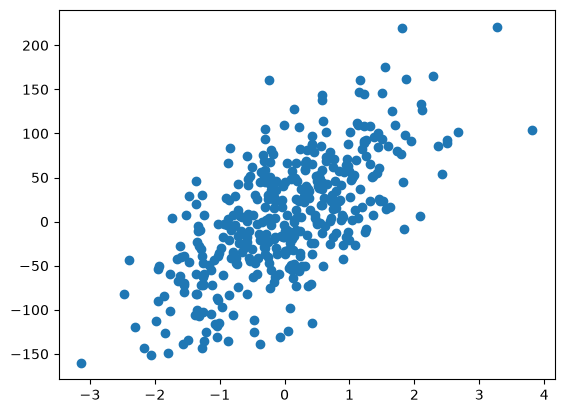

In [55]:
plt.scatter(X_train,y_train)


In [56]:
model = LinearRegression()
model.fit(X_train,y_train)
print(model.coef_)
print(model.intercept_)

[43.57741833]
4.669470214628861


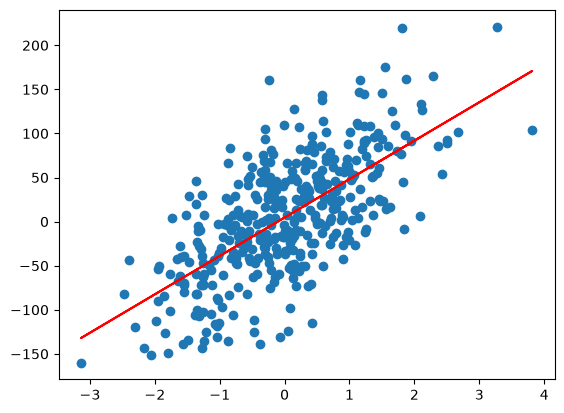

In [57]:
plt.plot(X_train,model.predict(X_train),color='red')
plt.scatter(X_train,y_train)

In [58]:
model2 = GD(0.001,200)
model2.fit(X_train,y_train)

43.57741832502343 4.669470214628863


In [59]:
y_pred = model2.predict(X_test)

In [60]:
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.45513634407746695

## Stochastic GD  

In [61]:
X = np.array([1,2,3,4,5],dtype=float)
y = np.array([3,5,7,9,11],dtype=float)

m = 0
b = 0

lr = 0.01
epochs = 100

loss_history = []
m_history = []
b_history = []

n = len(X)

for i in range(epochs):
    indices = np.random.permutation(n)
    for j in indices:
        y_pred = m * X[j] + b
        eror = y_pred - y[j]

        dm = eror * X[j]
        db = eror 

        m = m - lr * dm
        b = b - lr * db

    predictions = m *X+b
    loss = np.mean((y - predictions)**2)/2

    loss_history.append(loss)
    m_history.append(m)    
    b_history.append(b)

print("Final m:",m)    
print("Final b:",b)
print("Final loss:",loss_history[-1])    

Final m: 2.0504825667224753
Final b: 0.8130932585767068
Final loss: 0.0031771613462818343


# Check point 2

In [62]:
from sklearn.datasets import load_diabetes

X,y = load_diabetes(return_X_y=True)

d1,d2,d3,d4 = train_test_split(X,y,test_size=0.2,random_state=25)

In [63]:
f2 = LinearRegression()
f2.fit(d1,d3)
print(f2.coef_)
print(f2.intercept_)

[  -4.4110389  -176.14975887  515.70916826  415.68912805 -682.69131823
  328.41582506   92.97442489  210.1419437   700.10965675    4.96125582]
151.96412304279053


In [64]:
y_pred = f2.predict(d2)
r2_score(d4,y_pred)

0.4373000617984172

In [65]:
class SGDRegressor:

    def __init__(self,learning_rate=0.01,epochs=100):
        self.intercept_ = None
        self.coef_ = None
        self.LR=learning_rate
        self.EP=epochs


    def fit(self,X_train,y_train):
        self.intercept_ = 0
        self.coef_ = np.ones(X_train.shape[1])
        
        for i in range(self.EP):

            indices = np.random.permutation(X_train.shape[0])
            for idx in indices:
                y_pred = self.intercept_ + np.dot(X_train[idx],self.coef_ )
                intercept_der = -2 * (y_train[idx] - y_pred)
                self.intercept_ = self.intercept_ - self.LR * intercept_der

                coef_der = -2 *np.dot((y_train[idx] - y_pred),X_train[idx])
                self.coef_ = self.coef_ - self.LR * coef_der

        print(self.coef_,self.intercept_)

    def predict(self,X_test):
        return np.dot(X_test,self.coef_) + self.intercept_       

In [66]:
f3 = SGDRegressor(learning_rate=0.1,epochs=50)

In [67]:
f3.fit(d1,d3)
y_pred3 =f3.predict(d2)
r2_score(d4,y_pred3)

[   1.21845191 -168.67834473  521.77010673  417.5853965   -79.21465451
 -143.85860533 -178.37367406  119.73856554  481.32041733   10.90158579] 171.0701388410196


0.3554089511161421